# task 1

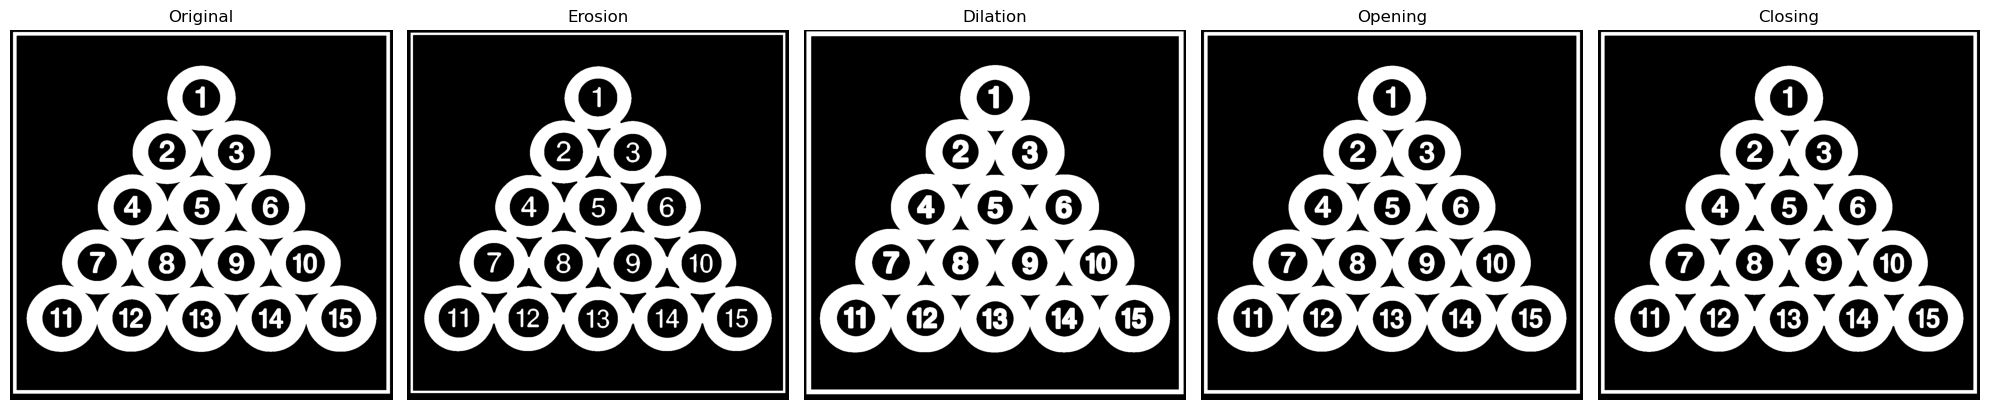

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("Balls(1).png", cv2.IMREAD_GRAYSCALE)
_, binary = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

kernel = np.ones((5, 5), np.uint8)

erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

images = [binary, erosion, dilation, opening, closing]
titles = ["Original", "Erosion", "Dilation", "Opening", "Closing"]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# task 2

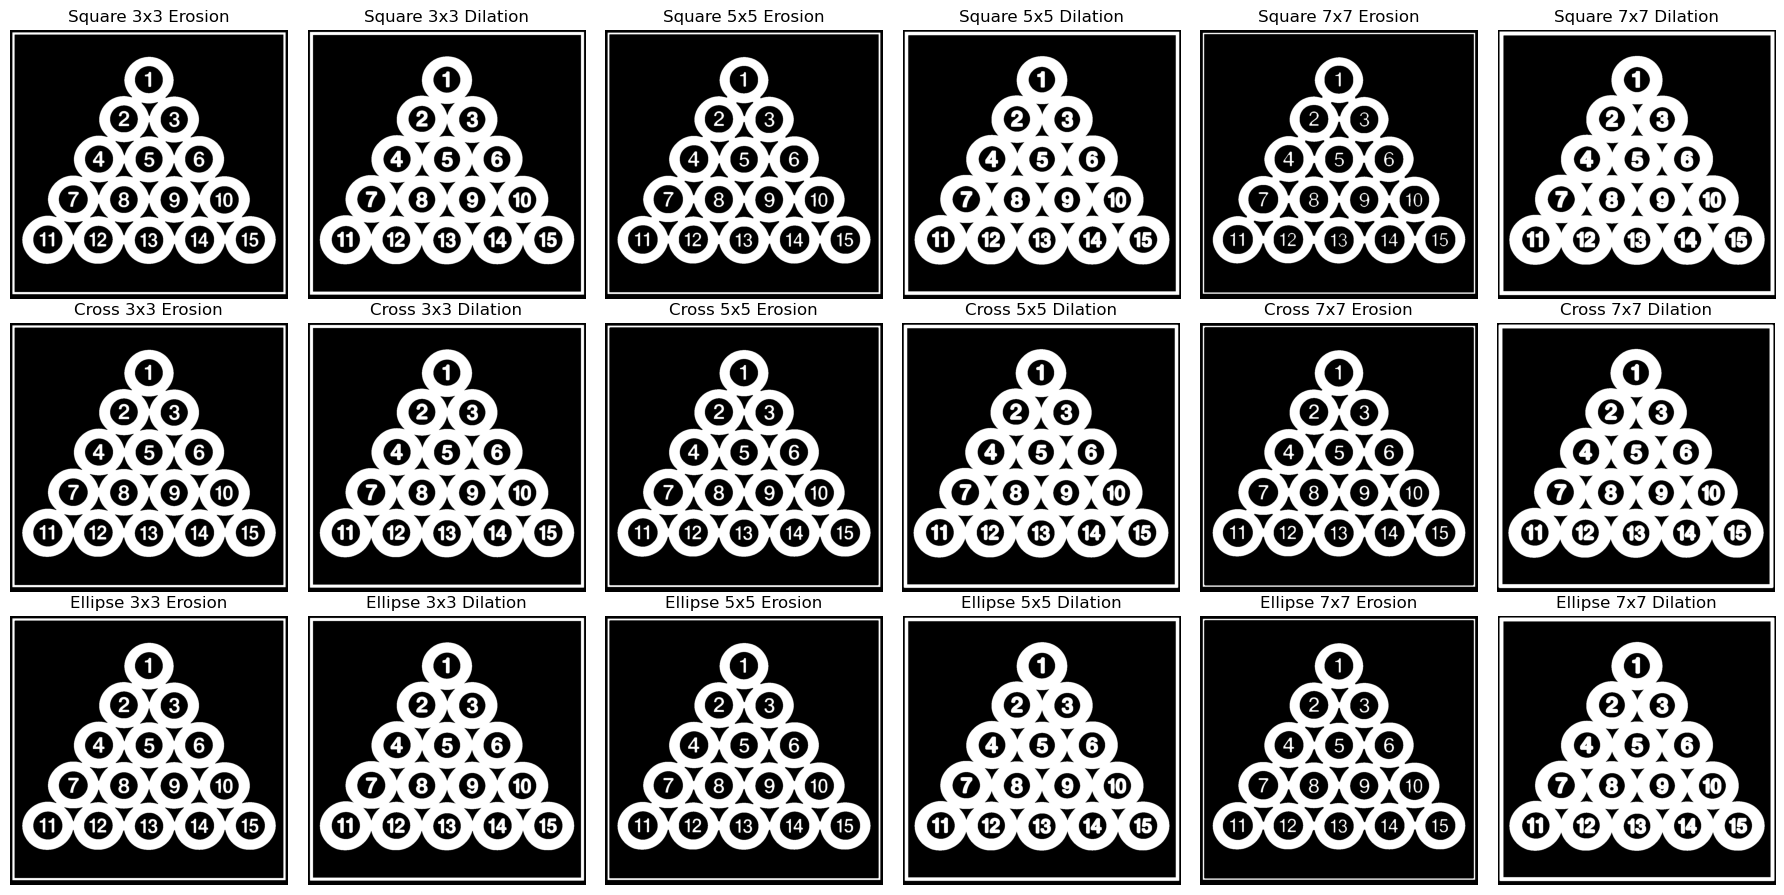

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("Balls(1).png", cv2.IMREAD_GRAYSCALE)
_, binary = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

shapes = {
    "Square": cv2.MORPH_RECT,
    "Cross": cv2.MORPH_CROSS,
    "Ellipse": cv2.MORPH_ELLIPSE
}

sizes = [3, 5, 7]

fig, axes = plt.subplots(3, 6, figsize=(18, 9))

for row, (shape_name, shape_type) in enumerate(shapes.items()):
    for col, size in enumerate(sizes):
        kernel = cv2.getStructuringElement(shape_type, (size, size))
        erosion = cv2.erode(binary, kernel, iterations=1)
        dilation = cv2.dilate(binary, kernel, iterations=1)

        axes[row, col * 2].imshow(erosion, cmap="gray")
        axes[row, col * 2].set_title(f"{shape_name} {size}x{size} Erosion")
        axes[row, col * 2].axis("off")

        axes[row, col * 2 + 1].imshow(dilation, cmap="gray")
        axes[row, col * 2 + 1].set_title(f"{shape_name} {size}x{size} Dilation")
        axes[row, col * 2 + 1].axis("off")

plt.tight_layout()
plt.show()